# Model training demo: gated attention-MIL, built from scratch (rung 5)

This notebook shows the project's deep-learning model being built and trained. The network is a **gated attention
multiple-instance learning (MIL) model** (Ilse et al., 2018), defined and trained **from scratch in PyTorch**
(`05_training/mil.py`; no pretrained weights in the network). Its inputs are frozen DINOv2-small frame vectors made
upstream by `04_pipeline_design/embed_tiles.py`.

- **Bag** = one street segment. **Instances** = its kept dashcam frames (one 768-number vector each). **Label** = the
  segment's 2023 PCI / 100.
- **What the notebook does:** (1) builds the network and checks it; (2) trains it on the training streets of one
  leave-street-out fold, with the hyperparameters the inner cross-validation chose for that fold, and records the
  error on the training bags and on the held-out streets after every epoch; (3) checks that it reproduces the
  predictions `ladder.py` made for that fold; (4) lists the hyperparameters chosen in every fold of the full run.
- **What it is not:** the evaluation. Every reported result comes from `05_training/ladder.py` (nested grouped
  cross-validation, leave-street-out and leave-area-out, 280 MIL training runs; log in `05_training/logs/`). This is a
  diagnostic on one fold, run after the feature freeze (2026-11-15); nothing here changes a model choice.
- **Run:** `pavement` environment, from VS Code (Restart & Run All) or
  `jupyter nbconvert --to notebook --execute --inplace 05_training/mil_training_demo.ipynb`. About 1-2 minutes on CPU.
  Needs the git-ignored analysis tables in `data/modeling_4C/`.

In [1]:
# Setup: find the project root, import the project's own modules, fix the device
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())
sys.path.insert(0, str(ROOT / "05_training"))
import mil      # the network: make_model, train, predict, standardizer
import ladder   # the evaluation: data loading and folds for rungs 1-5

if "pavement" not in sys.executable:
    print(f"WARNING: this kernel is {sys.executable}; use the pavement environment")
DATA = ROOT / "data/modeling_4C"        # the frozen analysis set (173 primary segments)
RUN = DATA / "ladder/frozen_mil"        # outputs of the main ladder run (Day 5)
DEV = "cpu"                             # MIL trains on CPU: repeatable bit for bit (mps is not)
print(f"python {sys.version.split()[0]} | torch {torch.__version__} | project {ROOT.name} | training device {DEV}")

python 3.12.15 | torch 2.15.0 | project pavement_index | training device cpu


In [2]:
# The network, built from scratch: print its layers and count its parameters
D_IN = 768                              # frame vector = DINOv2-small CLS token (384) + mean of patch tokens (384)
model = mil.make_model(D_IN, dropout=0.25)
print(model)
print(f"\ntrainable parameters: {sum(p.numel() for p in model.parameters()):,}")

# shape check on a dummy padded batch: 2 bags of 5 slots, the second bag has 2 padded (empty) slots
x = torch.randn(2, 5, D_IN)
mask = torch.tensor([[1, 1, 1, 1, 1], [1, 1, 1, 0, 0]], dtype=torch.bool)
model.eval()
with torch.no_grad():
    y_hat, att = model(x, mask)
print(f"output shape {tuple(y_hat.shape)} (one PCI/100 per bag) | attention shape {tuple(att.shape)} (one weight per frame)")
print(f"attention weights sum to 1 in each bag: {att.sum(1).numpy().round(6)} | weights on the padded slots: {att[1, 3:].numpy()}")

GatedAttentionMIL(
  (feat): Sequential(
    (0): Linear(in_features=768, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.25, inplace=False)
  )
  (V): Linear(in_features=128, out_features=64, bias=True)
  (U): Linear(in_features=128, out_features=64, bias=True)
  (w): Linear(in_features=64, out_features=1, bias=True)
  (head): Linear(in_features=128, out_features=1, bias=True)
)

trainable parameters: 115,138
output shape (2,) (one PCI/100 per bag) | attention shape (2, 5) (one weight per frame)
attention weights sum to 1 in each bag: [1. 1.] | weights on the padded slots: [0. 0.]


In [3]:
# mil.py's built-in self-test on synthetic bags (about 30 s): the PyTorch forward pass equals a plain-numpy
# reference, padded slots never affect a prediction, and the network learns (loss far below a mean predictor's)
mil.selftest()

SELFTEST OK | device mps
  torch vs numpy forward: max diff 2.2e-08 (want < 1e-4)
  bag alone vs padded batch: diff 7.5e-09 (want < 1e-5) | max weight on padded slots 0.0 (want 0)
  learning: loss 0.1610 -> 0.0028 vs mean-predictor 0.0675 (want < 25% of it)
  attention on distress frames: 1.51x the uniform weight (informational, not a pass/fail check)


**Checkpoint 1: the model is built and behaves correctly.** Each frame vector passes through one hidden layer
(768 → 128, ReLU, dropout). A gated attention branch (tanh ⊙ sigmoid, 64 units, then one score per frame) rates
every frame, and a softmax over the bag's real frames turns the scores into weights that sum to 1; padded slots get
exactly zero weight. The weighted average of the hidden vectors goes through a linear output layer (128 → 1) to give
PCI/100. The network is deliberately small (about 115,000 trainable parameters): there are only 173 labeled
segments, and the hard part, seeing the road, is done by the frozen DINOv2 backbone upstream. The self-test confirms
that the PyTorch code matches an independent numpy implementation, that padding never leaks into a prediction, and
that the network can learn a bag-level label.

In [4]:
# The frozen analysis set and the first leave-street-out fold (the same folds ladder.py uses)
d = ladder.load(DATA / "trim30")
bags, y, streets = d["bags"], d["y"], d["streets"]
sizes = np.array([len(b[1]) for b in bags])
print(f"{len(bags)} segments (bags) on {len(np.unique(streets))} streets | frames per bag: min {sizes.min()}, "
      f"median {int(np.median(sizes))}, max {sizes.max()} | {sizes.sum():,} frames | {bags[0][1].shape[1]} numbers per frame")

groups, outer, k_in = ladder.folds(d, "street")
FOLD = 0
tr, te = outer[FOLD]
print(f"fold {FOLD + 1} of {len(outer)}: training {len(tr)} segments on {len(np.unique(streets[tr]))} streets | "
      f"held out {len(te)} segments on {len(np.unique(streets[te]))} streets | "
      f"streets in both: {len(set(streets[tr]) & set(streets[te]))}")

choices = pd.read_csv(RUN / "mil_choices.csv")
ch = choices[(choices["scheme"] == "street") & (choices["fold"] == FOLD)].iloc[0]
DROPOUT, WD, EPOCHS = float(ch["dropout"]), float(ch["weight_decay"]), int(ch["epochs"])
print(f"chosen for this fold by the inner cross-validation (training streets only): "
      f"dropout {DROPOUT}, weight decay {WD:g}, {EPOCHS} epochs")

173 segments (bags) on 64 streets | frames per bag: min 3, median 10, max 87 | 2,586 frames | 768 numbers per frame
fold 1 of 5: training 138 segments on 51 streets | held out 35 segments on 13 streets | streets in both: 0
chosen for this fold by the inner cross-validation (training streets only): dropout 0.5, weight decay 0.01, 100 epochs


In [5]:
# Train from scratch on the training streets for 200 epochs (the longest setting in the grid) with the frozen
# settings: MSE loss on PCI/100, Adam (learning rate 1e-3), mini-batches of 16 padded bags, seed 0, CPU.
# After every epoch, record the error on the training bags and on the held-out streets (eval mode: no dropout).
torch.use_deterministic_algorithms(True)
train_bags, held_bags = [bags[i] for i in tr], [bags[i] for i in te]
y_tr, y_te = np.array([b[2] for b in train_bags]), np.array([b[2] for b in held_bags])
mu, sd = mil.standardizer(train_bags)          # standardization fitted on the training bags only
torch.manual_seed(ladder.SEED)                 # before the model is built: the initial weights are drawn here
net = mil.make_model(bags[0][1].shape[1], dropout=DROPOUT)
rows, held_at_choice = [], {}

def record(ep, m):
    p_tr = mil.predict(m, train_bags, mu, sd, DEV)[0]
    p_te = mil.predict(m, held_bags, mu, sd, DEV)[0]
    rows.append(dict(epoch=ep, train_mse=float(np.mean((p_tr - y_tr) ** 2)), held_mse=float(np.mean((p_te - y_te) ** 2)),
                     train_mae=float(100 * np.mean(np.abs(p_tr - y_tr))), held_mae=float(100 * np.mean(np.abs(p_te - y_te)))))
    if ep == EPOCHS:
        held_at_choice["pred"] = 100 * p_te    # the model ladder.py refitted for this fold stops here

t0 = time.time()
train_loss = mil.train(net, train_bags, mu, sd, DEV, epochs=200, weight_decay=WD, seed=ladder.SEED, on_epoch=record)
hist = pd.DataFrame(rows).assign(train_loss=train_loss)
print(f"200 epochs in {time.time() - t0:.1f} s on {DEV} | training loss (MSE on PCI/100, dropout on): "
      f"epoch 1 {train_loss[0]:.4f} -> epoch 200 {train_loss[-1]:.4f}")

200 epochs in 9.0 s on cpu | training loss (MSE on PCI/100, dropout on): epoch 1 0.1287 -> epoch 200 0.0069


same predictions as ladder.py for the 35 held-out segments at epoch 100: max difference 0.0e+00 PCI points -> YES
held-out MAE (PCI points) at the grid's epoch settings: 50: 19.1 | 100: 13.7 | 200: 14.0 | training MAE at 200: 5.2


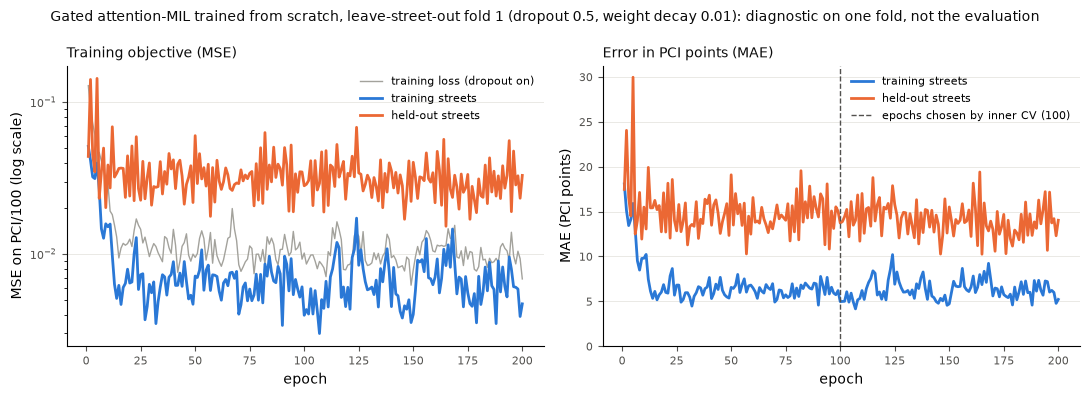

saved: 05_training/figures/mil_training_curves.png


In [6]:
# Check: does this run reproduce ladder.py's out-of-fold MIL predictions for this fold?
oof = pd.read_csv(RUN / "oof_predictions.csv").set_index("seg_key").loc[d["keys"]]
ref = oof["street | 5 attention-MIL"].to_numpy()[te]
diff = float(np.abs(held_at_choice["pred"] - ref).max())
print(f"same predictions as ladder.py for the {len(te)} held-out segments at epoch {EPOCHS}: max difference "
      f"{diff:.1e} PCI points -> {'YES' if diff < 1e-3 else 'NO (check library versions)'}")
h = hist.set_index("epoch")
print("held-out MAE (PCI points) at the grid's epoch settings: "
      + " | ".join(f"{e}: {h.loc[e, 'held_mae']:.1f}" for e in ladder.MIL_EPOCHS)
      + f" | training MAE at 200: {h.loc[200, 'train_mae']:.1f}")

# Learning curves (diagnostic; the number of epochs was chosen by the inner CV, never from these curves)
BLUE, ORANGE, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#a3a29c", "#0b0b0b", "#52514e"
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
e = hist["epoch"]
ax[0].plot(e, hist["train_loss"], color=GREY, lw=1, label="training loss (dropout on)")
ax[0].plot(e, hist["train_mse"], color=BLUE, lw=2, label="training streets")
ax[0].plot(e, hist["held_mse"], color=ORANGE, lw=2, label="held-out streets")
ax[0].set(yscale="log", xlabel="epoch", ylabel="MSE on PCI/100 (log scale)")
ax[0].set_title("Training objective (MSE)", loc="left", fontsize=10, color=INK)
ax[1].plot(e, hist["train_mae"], color=BLUE, lw=2, label="training streets")
ax[1].plot(e, hist["held_mae"], color=ORANGE, lw=2, label="held-out streets")
ax[1].axvline(EPOCHS, color=MUTED, lw=1, ls="--", label=f"epochs chosen by inner CV ({EPOCHS})")
ax[1].set(xlabel="epoch", ylabel="MAE (PCI points)", ylim=(0, None))
ax[1].set_title("Error in PCI points (MAE)", loc="left", fontsize=10, color=INK)
for a in ax:
    a.legend(frameon=False, fontsize=8)
    a.spines[["top", "right"]].set_visible(False)
    a.grid(axis="y", color="#e6e5e0", lw=0.6)
    a.tick_params(colors=MUTED, labelsize=8)
fig.suptitle(f"Gated attention-MIL trained from scratch, leave-street-out fold {FOLD + 1} "
             f"(dropout {DROPOUT}, weight decay {WD:g}): diagnostic on one fold, not the evaluation",
             fontsize=10, color=INK)
fig.tight_layout()
out = ROOT / "05_training/figures/mil_training_curves.png"
out.parent.mkdir(exist_ok=True)
fig.savefig(out, dpi=200, bbox_inches="tight")
plt.show()
print(f"saved: {out.relative_to(ROOT)}")

**Checkpoint 2: how to read the curves.** The training curves (blue) show the network fitting its training streets;
the held-out curves (orange) show its error on streets it never saw in this fold. The gap between them is how much
the network memorizes: with about 140 training segments and about 115,000 parameters it can drive its training error
far below its held-out error. That is why dropout, weight decay and the number of epochs were not fixed by hand but
tuned in the inner cross-validation, on the training streets only. The held-out curve is shown here for diagnosis
only. Choosing the epoch count from it would leak the held-out fold into the model, so the dashed line marks what
the inner cross-validation chose without seeing these streets. The reproduction check confirms that this notebook
trains exactly the model that `ladder.py` evaluated for this fold.

In [7]:
# Model optimization: the setting the inner cross-validation chose in every outer fold of the main run
# grid = dropout {0.25, 0.5} x weight decay {1e-4, 1e-3, 1e-2} x epochs {50, 100, 200} (18 settings), lowest pooled inner MAE
print("dropout x weight decay:", ladder.MIL_GRID, "| epochs read at checkpoints:", ladder.MIL_EPOCHS)
choices

dropout x weight decay: [(0.25, 0.0001), (0.25, 0.001), (0.25, 0.01), (0.5, 0.0001), (0.5, 0.001), (0.5, 0.01)] | epochs read at checkpoints: (50, 100, 200)


,scheme,fold,dropout,weight_decay,epochs,inner_MAE,inner_folds,test_segments
0,street,0,0.50,0.0100,100,16.797,5,35
1,street,1,0.50,0.0001,200,14.734,5,35
2,street,2,0.50,0.0001,200,14.621,5,35
3,street,3,0.25,0.0010,200,15.666,5,34
4,street,4,0.50,0.0010,200,16.793,5,34
5,area,0,0.50,0.0100,200,22.576,4,62
6,area,1,0.50,0.0100,200,22.327,4,45
7,area,2,0.50,0.0010,200,13.120,4,23
8,area,3,0.25,0.0001,100,18.303,4,22
9,area,4,0.25,0.0001,100,15.391,4,21


**Checkpoint 3: where this sits in the repository.** The network and its training loop are in `05_training/mil.py`.
`05_training/ladder.py` trains and evaluates every model of the ladder on the same segments and folds; hyperparameter
optimization happens inside its nested cross-validation (see `06_optimization/README.md`). The table above shows
that the search did not settle on one setting: each outer fold picked its own combination from its own training
streets, which is expected with 173 segments. The numbers reported in the project report come from the full run
logged in `05_training/logs/ladder_run_frozen_mil.txt`, not from this notebook.